In [2]:
# Building the SDWPF competition metric from the ground up, using the trained GRU models.
import os, sys, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "windevolve_sdwpf"))
if not os.path.isdir(REPO):
    REPO = os.getcwd()
if REPO not in sys.path:
    sys.path.insert(0, REPO)

import metrics
from test_data import TestData
import evaluator as EV
import baseline_models.gru.gru_baseline as G

TEST_DIR = EV.TEST_DIR
CKPT_DIR = G.CHECKPOINTS
CAPACITY, HORIZON = 134, 288
N_WINDOWS = None                 # None = all windows; set to 20 for a fast pass

np.random.seed(1)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

trained = sorted(int(os.path.basename(p).split("_")[1].split(".")[0])
                 for p in glob.glob(os.path.join(CKPT_DIR, "model_*.pt")))
SUBSET = trained
print("trained turbines :", SUBSET, "({} of {})".format(len(SUBSET), CAPACITY))

trained turbines : [0, 1, 2] (3 of 134)


In [3]:
# What the model receives
infiles = sorted(glob.glob(os.path.join(TEST_DIR, "infile", "*in.csv")))
outfiles = sorted(glob.glob(os.path.join(TEST_DIR, "outfile", "*out.csv")))
n_win = len(infiles) if N_WINDOWS is None else min(N_WINDOWS, len(infiles))

sample = pd.read_csv(infiles[0])
steps_per_turbine = len(sample) // sample.TurbID.nunique()
roles = ["label"] * 3 + ["model input"] * 9 + ["input + target"]
meanings = ["turbine id", "day index (local to window)", "time of day",
            "wind speed (m/s)", "wind dir vs nacelle (deg)", "ambient temp (C)",
            "nacelle temp (C)", "nacelle direction (deg)", "pitch blade 1 (deg)",
            "pitch blade 2 (deg)", "pitch blade 3 (deg)", "reactive power (kW)",
            "active power (kW) - the target"]
print("Infile Columns ")
print(pd.DataFrame({"column": sample.columns, "role": roles,
                    "meaning": meanings}).to_string(index=False))
print()
print("infiles          : {}".format(len(infiles)))
print("outfiles         : {}".format(len(outfiles)))
print("windows used     : {}".format(n_win))
print("infile rows      : {:,} = {} turbines x {} steps ({} days x 144)".format(
    len(sample), sample.TurbID.nunique(), steps_per_turbine, steps_per_turbine // 144))

Infile Columns 
 column           role                        meaning
 TurbID          label                     turbine id
    Day          label    day index (local to window)
Tmstamp          label                    time of day
   Wspd    model input               wind speed (m/s)
   Wdir    model input      wind dir vs nacelle (deg)
   Etmp    model input               ambient temp (C)
   Itmp    model input               nacelle temp (C)
   Ndir    model input        nacelle direction (deg)
   Pab1    model input            pitch blade 1 (deg)
   Pab2    model input            pitch blade 2 (deg)
   Pab3    model input            pitch blade 3 (deg)
   Prtv    model input            reactive power (kW)
   Patv input + target active power (kW) - the target

infiles          : 142
outfiles         : 142
windows used     : 142
infile rows      : 270,144 = 134 turbines x 2016 steps (14 days x 144)


In [4]:
# Load the trained models and predict one window.
device = torch.device("cpu")
models, scalers, settings = {}, {}, None
for tid in SUBSET:
    blob = torch.load(os.path.join(CKPT_DIR, "model_{}.pt".format(tid)),
                      map_location=device, weights_only=False)
    settings = blob["settings"]
    m = G.BaselineGruModel(settings).to(device)
    m.load_state_dict(blob["state_dict"]); m.eval()
    models[tid] = m
    scalers[tid] = (blob["scaler_mean"], blob["scaler_std"])

def predict_window(path_to_infile, tids):
    td = TestData(path_to_data=path_to_infile, start_col=settings["start_col"],
                  farm_capacity=CAPACITY)
    out, shapes = {}, {}
    with torch.no_grad():
        for tid in tids:
            seq, _ = td.get_turbine(tid)
            mean, std = scalers[tid]
            norm = (np.asarray(seq, dtype=np.float32) - mean) / std
            used = norm[-settings["input_len"]:]
            p = models[tid](torch.from_numpy(used).float().unsqueeze(0)).squeeze(0).squeeze(-1)
            out[tid] = p.cpu().numpy() * std + mean
            shapes[tid] = (seq.shape, used.shape, out[tid].shape)
    return out, shapes

def truth_window(path_to_outfile, tids):
    td = TestData(path_to_data=path_to_outfile, start_col=settings["start_col"],
                  farm_capacity=CAPACITY)
    seqs, raws = td.get_all_turbines()
    return {tid: (np.asarray(seqs[tid][:HORIZON, -1], dtype=float), raws[tid]) for tid in tids}

pred0, shapes0 = predict_window(infiles[0], SUBSET)
true0 = truth_window(outfiles[0], SUBSET)
TID = SUBSET[0]
in_shape, used_shape, out_shape = shapes0[TID]
gt0, raw0 = true0[TID]

print("SHAPES FOR TURBINE {} IN ONE WINDOW".format(TID))
print(pd.DataFrame({
    "quantity": ["history available", "history fed to model", "prediction", "ground truth"],
    "shape": [str(in_shape), str(used_shape), str(out_shape), str(gt0.shape)],
    "units": ["mixed (raw)", "normalized", "kW", "kW"],
    "steps": [in_shape[0], used_shape[0], out_shape[0], gt0.shape[0]],
    "hours": [round(in_shape[0] / 6), round(used_shape[0] / 6),
              round(out_shape[0] / 6), round(gt0.shape[0] / 6)],
}).to_string(index=False))

SHAPES FOR TURBINE 0 IN ONE WINDOW
            quantity      shape       units  steps  hours
   history available (2016, 10) mixed (raw)   2016    336
history fed to model  (144, 10)  normalized    144     24
          prediction     (288,)          kW    288     48
        ground truth     (288,)          kW    288     48


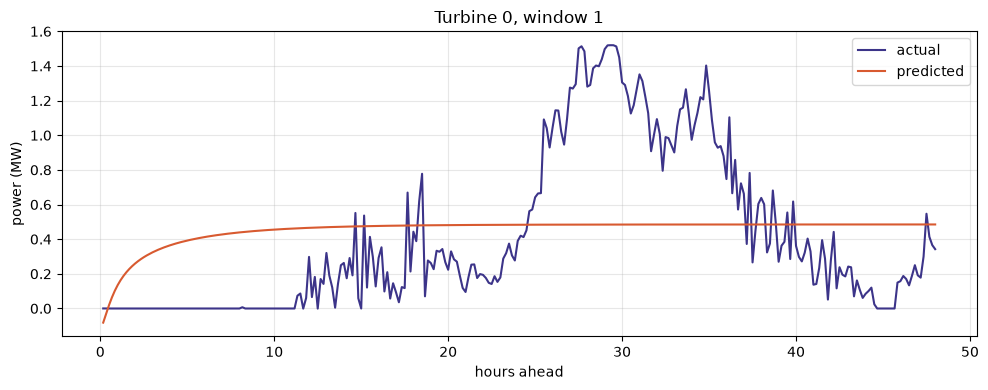

FIRST 6 OF 288 STEPS
 step  actual_kW  predicted_kW  error_kW
    1        0.0    -81.870003    -81.87
    2       -0.3    -30.650000    -30.35
    3       -0.3     19.010000     19.31
    4       -0.3     63.410000     63.71
    5       -0.3    101.930000    102.23
    6       -0.3    135.009995    135.31


In [5]:
# Prediction against truth, for one turbine in one window.
pred = pred0[TID]
gt = gt0
hours = np.arange(1, HORIZON + 1) * 10 / 60.0

plt.figure()
plt.plot(hours, gt / 1000, color="#3C3489", lw=1.5, label="actual")
plt.plot(hours, pred / 1000, color="#D85A30", lw=1.5, label="predicted")
plt.xlabel("hours ahead"); plt.ylabel("power (MW)")
plt.title("Turbine {}, window 1".format(TID))
plt.legend(); plt.tight_layout(); plt.show()

print("FIRST 6 OF {} STEPS".format(HORIZON))
print(pd.DataFrame({"step": np.arange(1, 7),
                    "actual_kW": np.round(gt[:6], 2),
                    "predicted_kW": np.round(pred[:6], 2),
                    "error_kW": np.round(pred[:6] - gt[:6], 2)}).to_string(index=False))

In [6]:
# Which steps are excluded by the official rules, and why.
raw = raw0.reset_index(drop=True)
r_nan = pd.isna(raw).any(axis=1).to_numpy()
r_neg = (raw["Patv"] < 0).to_numpy()
r_stop = ((raw["Patv"] == 0) & (raw["Wspd"] > 2.5)).to_numpy()
r_pitch = ((raw["Pab1"] > 89) | (raw["Pab2"] > 89) | (raw["Pab3"] > 89)).to_numpy()
r_sensor = ((raw["Wdir"] < -180) | (raw["Wdir"] > 180)
            | (raw["Ndir"] < -720) | (raw["Ndir"] > 720)).to_numpy()
keep = ~(r_nan | r_neg | r_stop | r_pitch | r_sensor)

print("MASKING FOR TURBINE {}, WINDOW 1  (rules overlap, so counts do not add up)".format(TID))
print(pd.DataFrame({
    "rule": ["any NaN in row", "Patv < 0", "Patv == 0 and Wspd > 2.5",
             "any Pab > 89", "|Wdir| > 180 or |Ndir| > 720", "KEPT"],
    "means": ["missing reading", "bad reading", "turbine stopped",
              "blades feathered", "sensor out of range", "scored"],
    "steps": [int(r_nan.sum()), int(r_neg.sum()), int(r_stop.sum()),
              int(r_pitch.sum()), int(r_sensor.sum()), int(keep.sum())],
}).to_string(index=False))
print()
print("scored steps: {} of {} ({:.0f}%)".format(keep.sum(), HORIZON, 100 * keep.mean()))

MASKING FOR TURBINE 0, WINDOW 1  (rules overlap, so counts do not add up)
                        rule               means  steps
              any NaN in row     missing reading      1
                    Patv < 0         bad reading     75
    Patv == 0 and Wspd > 2.5     turbine stopped      0
                any Pab > 89    blades feathered     67
|Wdir| > 180 or |Ndir| > 720 sensor out of range      0
                        KEPT              scored    212

scored steps: 212 of 288 (74%)


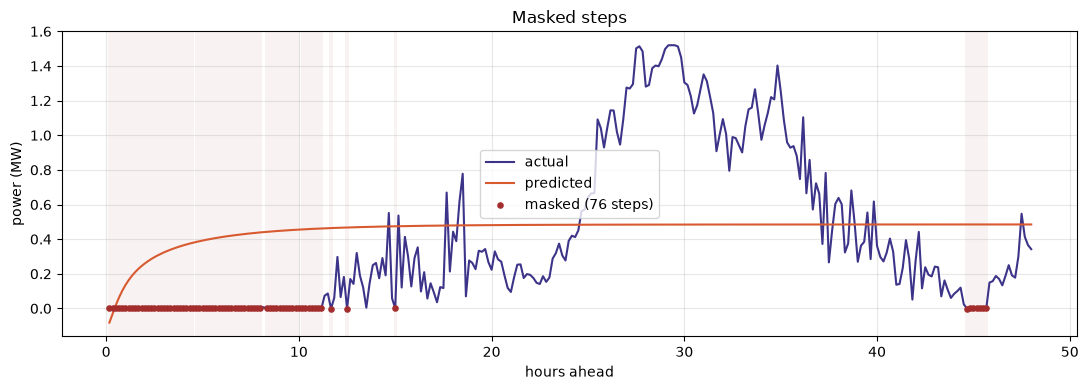

MASKED ROWS (first 12 of 76), all columns
 step       rule  TurbID  Day Tmstamp  Wspd   Wdir  Etmp  Itmp   Ndir  Pab1  Pab2  Pab3  Prtv  Patv
    1 NaN in row       1   15   00:00   NaN    NaN   NaN   NaN    NaN   NaN   NaN   NaN   NaN   NaN
    2   Patv < 0       1   15   00:10  1.32 -14.75 20.74 33.52 -93.07 90.36 90.39 90.37  -0.3  -0.3
    3   Patv < 0       1   15   00:20  1.29 -18.95 21.05 34.34 -93.07 90.36 90.39 90.37  -0.3  -0.3
    4   Patv < 0       1   15   00:30  1.65 -13.35 21.10 34.67 -93.07 90.36 90.39 90.37  -0.3  -0.3
    5   Patv < 0       1   15   00:40  1.64  -4.39 21.09 34.84 -93.07 90.36 90.39 90.37  -0.3  -0.3
    6   Patv < 0       1   15   00:50  1.73  -3.88 21.05 34.99 -93.07 90.36 90.39 90.37  -0.3  -0.3
    7   Patv < 0       1   15   01:00  1.71  -1.75 20.91 35.03 -93.07 90.36 90.39 90.37  -0.3  -0.3
    8   Patv < 0       1   15   01:10  2.15  -2.76 20.90 35.09 -93.07 90.36 90.39 90.37  -0.3  -0.3
    9   Patv < 0       1   15   01:20  2.20   2.13 20.90 3

In [7]:
# The same window, with the excluded steps marked.
plt.figure(figsize=(11, 4))
plt.plot(hours, gt / 1000, color="#3C3489", lw=1.5, label="actual")
plt.plot(hours, pred / 1000, color="#D85A30", lw=1.5, label="predicted")
masked = ~keep
plt.scatter(hours[masked], gt[masked] / 1000, s=14, color="#A32D2D",
            zorder=3, label="masked ({} steps)".format(masked.sum()))
for h in hours[masked]:
    plt.axvspan(h - 0.083, h + 0.083, color="#A32D2D", alpha=0.06, lw=0)
plt.xlabel("hours ahead"); plt.ylabel("power (MW)")
plt.title("Masked steps")
plt.legend(); plt.tight_layout(); plt.show()

rule_name = np.full(HORIZON, "", dtype=object)
rule_name[r_sensor] = "sensor range"
rule_name[r_pitch] = "pitch > 89"
rule_name[r_stop] = "stopped"
rule_name[r_neg] = "Patv < 0"
rule_name[r_nan] = "NaN in row"
idx = np.where(masked)[0]
show = raw.iloc[idx[:12]].copy()
show.insert(0, "step", idx[:12] + 1)
show.insert(1, "rule", rule_name[idx[:12]])
print("MASKED ROWS (first {} of {}), all columns".format(min(12, len(idx)), len(idx)))
print(show.to_string(index=False))

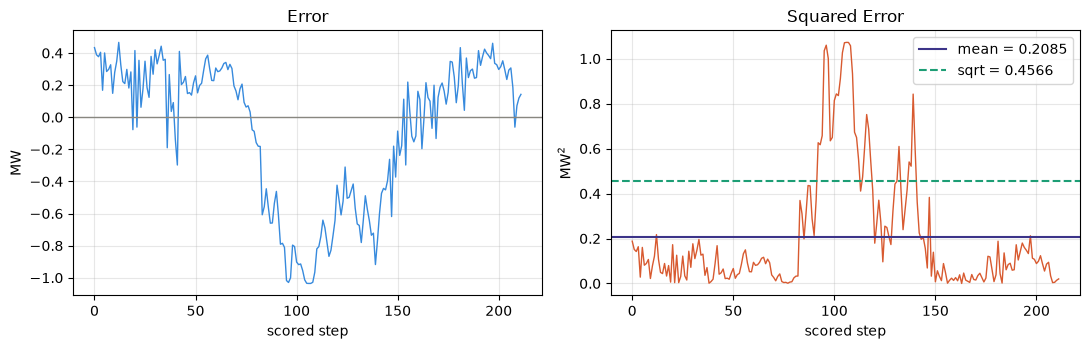

RMSE for turbine 0 in window 1
  scored steps        : 212
  mean squared error  : 0.208487 MW^2
  RMSE = sqrt(MSE)    : 0.456604 MW


In [8]:
# RMSE, built up one operation at a time (scored steps only, in MW).
err = (pred - gt) / 1000.0
e = err[keep]
sq = e ** 2
mse = sq.mean()
rmse = np.sqrt(mse)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(len(e)), e, color="#378ADD", lw=1)
ax[0].axhline(0, color="#888780", lw=1)
ax[0].set_title("Error"); ax[0].set_ylabel("MW"); ax[0].set_xlabel("scored step")
ax[1].plot(np.arange(len(sq)), sq, color="#D85A30", lw=1)
ax[1].axhline(mse, color="#3C3489", lw=1.5, label="mean = {:.4f}".format(mse))
ax[1].axhline(rmse, color="#1D9E75", lw=1.5, ls="--", label="sqrt = {:.4f}".format(rmse))
ax[1].set_title("Squared Error"); ax[1].set_ylabel("MW$^2$"); ax[1].set_xlabel("scored step")
ax[1].legend()
plt.tight_layout(); plt.show()

print("RMSE for turbine {} in window 1".format(TID))
print("  scored steps        : {}".format(len(e)))
print("  mean squared error  : {:.6f} MW^2".format(mse))
print("  RMSE = sqrt(MSE)    : {:.6f} MW".format(rmse))

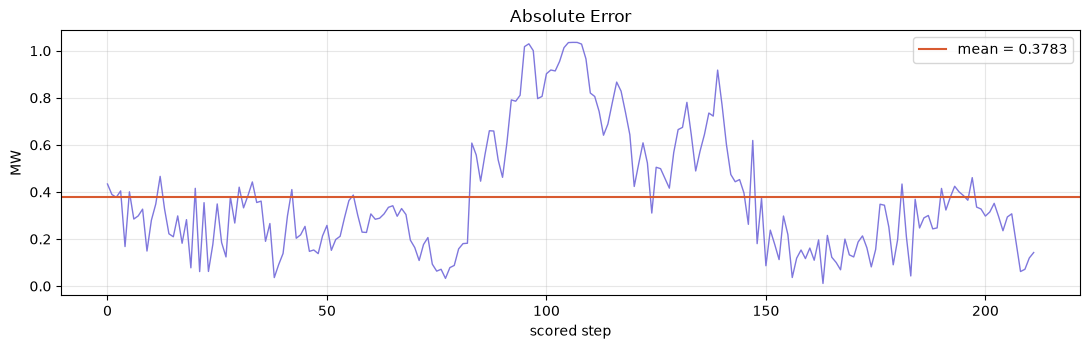

MAE for turbine 0 in window 1
  scored steps        : 212
  mean |error|        : 0.378277 MW


In [9]:
# MAE on the same steps.
ab = np.abs(e)
mae = ab.mean()

plt.figure(figsize=(11, 3.6))
plt.plot(np.arange(len(ab)), ab, color="#7F77DD", lw=1)
plt.axhline(mae, color="#D85A30", lw=1.5, label="mean = {:.4f}".format(mae))
plt.xlabel("scored step"); plt.ylabel("MW")
plt.title("Absolute Error"); plt.legend()
plt.tight_layout(); plt.show()

print("MAE for turbine {} in window 1".format(TID))
print("  scored steps        : {}".format(len(ab)))
print("  mean |error|        : {:.6f} MW".format(mae))

In [10]:
# Repeat for every trained turbine and every window.
tur_mae = np.full((n_win, len(SUBSET)), np.nan)
tur_rmse = np.full((n_win, len(SUBSET)), np.nan)
n_valid = np.zeros((n_win, len(SUBSET)))
abs_err_sum = np.zeros(HORIZON); abs_err_cnt = np.zeros(HORIZON)

t0 = time.perf_counter()
for k in range(n_win):
    pk, _ = predict_window(infiles[k], SUBSET)
    tk = truth_window(outfiles[k], SUBSET)
    for j, tid in enumerate(SUBSET):
        g, r = tk[tid]
        nc = pd.isna(r).any(axis=1).to_numpy()
        iv = ((r["Patv"] < 0) | ((r["Patv"] == 0) & (r["Wspd"] > 2.5))
              | (r["Pab1"] > 89) | (r["Pab2"] > 89) | (r["Pab3"] > 89)
              | (r["Wdir"] < -180) | (r["Wdir"] > 180)
              | (r["Ndir"] < -720) | (r["Ndir"] > 720)).to_numpy()
        kp = ~nc & ~iv
        er = (pk[tid] - g) / 1000.0
        n_valid[k, j] = kp.sum()
        if kp.sum() and np.any(pk[tid][kp]) and np.any(g[kp]):
            tur_mae[k, j] = np.abs(er[kp]).mean()
            tur_rmse[k, j] = np.sqrt((er[kp] ** 2).mean())
        abs_err_sum += np.where(kp, np.abs(er), 0.0)
        abs_err_cnt += kp.astype(float)
print("PER-TURBINE AVERAGES ACROSS {} WINDOWS".format(n_win))
print(pd.DataFrame({
    "turbine": SUBSET,
    "mean_MAE_MW": np.round(np.nanmean(tur_mae, axis=0), 4),
    "mean_RMSE_MW": np.round(np.nanmean(tur_rmse, axis=0), 4),
    "mean_steps_scored": np.round(n_valid.mean(axis=0), 1),
}).to_string(index=False))

PER-TURBINE AVERAGES ACROSS 142 WINDOWS
 turbine  mean_MAE_MW  mean_RMSE_MW  mean_steps_scored
       0       0.3622        0.4195              219.5
       1       0.3000        0.3573              213.9
       2       0.3700        0.4429              221.7


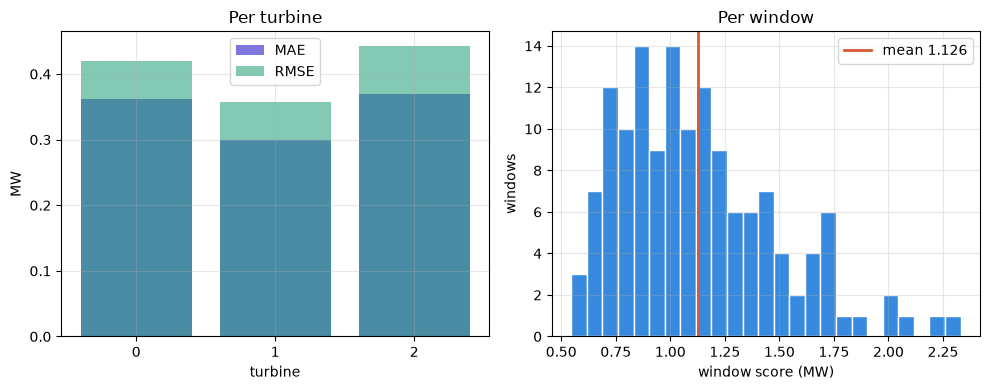

ORDER OF OPERATIONS
  sum turbines -> average windows : 1.125944   (what the official code does)
  average windows -> sum turbines : 1.125944
  difference                      : 2.22e-16

Both orders give the same answer, because summing and averaging are linear and
commute. They only diverge if some turbine-windows are skipped, since the two
orders then divide by different counts.

OVERALL SCORE  (3 turbines, 142 windows)
  MAE   : 1.032198 MW
  RMSE  : 1.219689 MW
  SCORE : 0.5 * (RMSE + MAE) = 1.125944 MW


In [11]:
# The overall score, and the order of operations.
# Official code: SUM over turbines to score each window, THEN average over windows.
win_mae = np.nansum(tur_mae, axis=1)
win_rmse = np.nansum(tur_rmse, axis=1)
score_sum_then_avg = 0.5 * (win_mae.mean() + win_rmse.mean())

# Other order: average each turbine over windows, THEN sum over turbines.
turb_mae = np.nanmean(tur_mae, axis=0)
turb_rmse = np.nanmean(tur_rmse, axis=0)
score_avg_then_sum = 0.5 * (turb_mae.sum() + turb_rmse.sum())

fig, ax = plt.subplots(1, 2)
ax[0].bar(np.arange(len(SUBSET)), turb_mae, color="#7F77DD", label="MAE")
ax[0].bar(np.arange(len(SUBSET)), turb_rmse, color="#1D9E75", alpha=0.55, label="RMSE")
ax[0].set_xticks(np.arange(len(SUBSET))); ax[0].set_xticklabels(SUBSET)
ax[0].set_xlabel("turbine"); ax[0].set_ylabel("MW")
ax[0].set_title("Per turbine"); ax[0].legend()
ax[1].hist(0.5 * (win_mae + win_rmse), bins=25, color="#378ADD", edgecolor="white")
ax[1].axvline(score_sum_then_avg, color="#D85A30", lw=2,
              label="mean {:.3f}".format(score_sum_then_avg))
ax[1].set_xlabel("window score (MW)"); ax[1].set_ylabel("windows")
ax[1].set_title("Per window"); ax[1].legend()
plt.tight_layout(); plt.show()

print("ORDER OF OPERATIONS")
print("  sum turbines -> average windows : {:.6f}   (what the official code does)".format(
    score_sum_then_avg))
print("  average windows -> sum turbines : {:.6f}".format(score_avg_then_sum))
print("  difference                      : {:.2e}".format(
    abs(score_sum_then_avg - score_avg_then_sum)))
print()
print("Both orders give the same answer, because summing and averaging are linear and")
print("commute. They only diverge if some turbine-windows are skipped, since the two")
print("orders then divide by different counts.")
print()
print("OVERALL SCORE  ({} turbines, {} windows)".format(len(SUBSET), n_win))
print("  MAE   : {:.6f} MW".format(win_mae.mean()))
print("  RMSE  : {:.6f} MW".format(win_rmse.mean()))
print("  SCORE : 0.5 * (RMSE + MAE) = {:.6f} MW".format(score_sum_then_avg))

In [12]:
# Scale check.
per_turbine_score = score_sum_then_avg / len(SUBSET)
print("this notebook    : {} turbines, score {:.4f} MW".format(len(SUBSET), score_sum_then_avg))
print("per turbine      : {:.4f} MW".format(per_turbine_score))
print("if all 134 alike : {:.1f} MW".format(per_turbine_score * CAPACITY))
print()
print("The last line is a sanity check only. Per-turbine error varies widely across the")
print("farm, and these models were trained for {} epoch(s).".format(settings["train_epochs"]))

this notebook    : 3 turbines, score 1.1259 MW
per turbine      : 0.3753 MW
if all 134 alike : 50.3 MW

The last line is a sanity check only. Per-turbine error varies widely across the
farm, and these models were trained for 1 epoch(s).


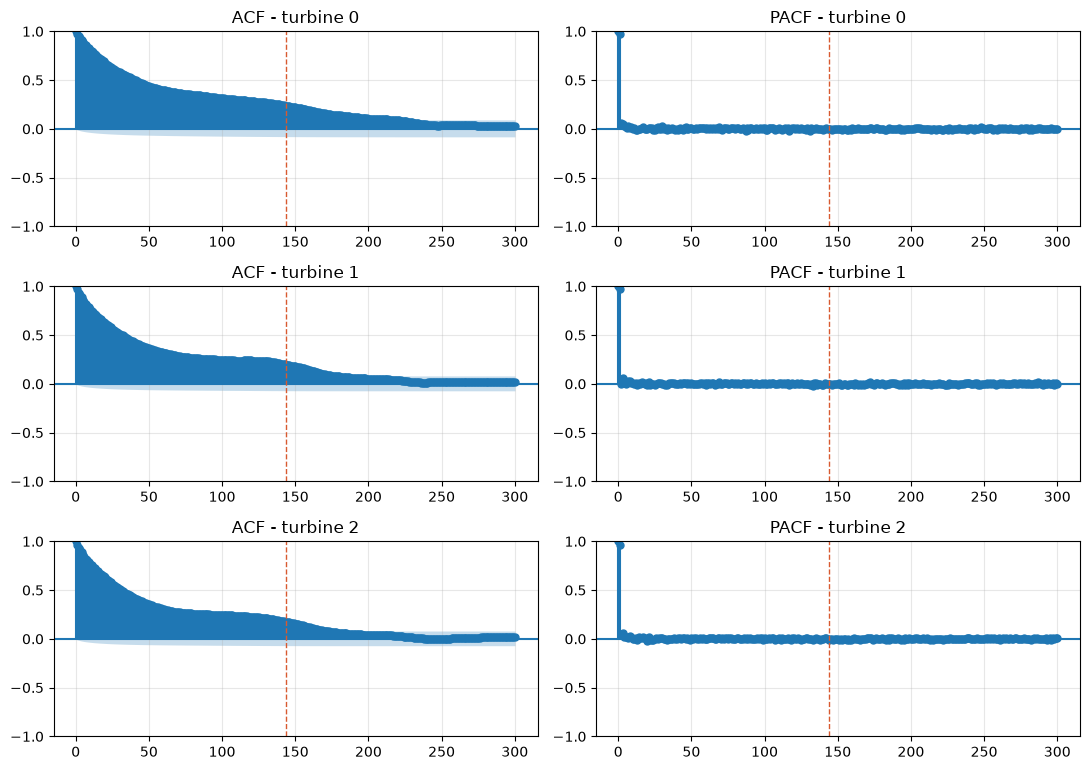

turbine   0 : ACF(lag 1) 0.972   ACF(lag 144) 0.238
turbine   1 : ACF(lag 1) 0.968   ACF(lag 144) 0.198
turbine   2 : ACF(lag 1) 0.966   ACF(lag 144) 0.175

PACF spike at lag 1 -> p=1; slow ACF decay -> d>=1; no bump at 144 -> non-seasonal.


In [13]:
# ACF / PACF on the training series, to choose the ARIMA order. Needs statsmodels.
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

TRAIN_CSV = EV.prep_env()["path_to_train"]
ACF_TURBINES = SUBSET[:3] if SUBSET else [0, 1, 2]
MAX_LAG = 300                                        # past the daily lag (144)

df_tr = pd.read_csv(TRAIN_CSV, usecols=["TurbID", "Patv"])
total_tr = len(df_tr) // CAPACITY
patv_tr = np.nan_to_num(df_tr["Patv"].to_numpy(dtype=float), nan=0.0)

fig, axes = plt.subplots(len(ACF_TURBINES), 2, figsize=(11, 2.6 * len(ACF_TURBINES)))
axes = np.atleast_2d(axes)
for row, tid in enumerate(ACF_TURBINES):
    s = patv_tr[tid * total_tr:(tid + 1) * total_tr]
    plot_acf(s, lags=MAX_LAG, ax=axes[row, 0], alpha=0.05)
    plot_pacf(s, lags=MAX_LAG, ax=axes[row, 1], alpha=0.05, method="ywm")
    axes[row, 0].axvline(144, color="#D85A30", ls="--", lw=1)
    axes[row, 1].axvline(144, color="#D85A30", ls="--", lw=1)
    axes[row, 0].set_title("ACF - turbine {}".format(tid))
    axes[row, 1].set_title("PACF - turbine {}".format(tid))
plt.tight_layout(); plt.show()

for tid in ACF_TURBINES:
    s = patv_tr[tid * total_tr:(tid + 1) * total_tr]
    print("turbine {:3d} : ACF(lag 1) {:.3f}   ACF(lag 144) {:.3f}".format(
        tid, np.corrcoef(s[1:], s[:-1])[0, 1], np.corrcoef(s[144:], s[:-144])[0, 1]))
print()
print("PACF spike at lag 1 -> p=1; slow ACF decay -> d>=1; no bump at 144 -> non-seasonal.")

In [14]:
# Augmented Dickey-Fuller test: formally choose the differencing order d.
# H0 = the series has a unit root (non-stationary, needs differencing).
#   p < 0.05  -> reject H0 -> stationary  -> this level of differencing is enough.
#   p >= 0.05 -> cannot reject -> difference once more and re-test.
from statsmodels.tsa.stattools import adfuller

def adf_d(series, max_d=2):
    """Return the smallest d in 0..max_d that makes the series stationary (ADF p<0.05)."""
    x = series.astype(float)
    for d in range(max_d + 1):
        stat, p = adfuller(x, autolag="AIC")[:2]
        yield d, stat, p
        if p < 0.05:
            return
        x = np.diff(x)

print("ADF TEST PER TURBINE  (raw series, then differenced until stationary)")
print("{:>8} {:>4} {:>12} {:>10}  {}".format("turbine", "d", "ADF stat", "p-value", "verdict"))
chosen = []
for tid in ACF_TURBINES:
    s = patv_tr[tid * total_tr:(tid + 1) * total_tr]
    for d, stat, p in adf_d(s):
        verdict = "stationary" if p < 0.05 else "unit root -> difference"
        print("{:>8} {:>4} {:>12.3f} {:>10.4g}  {}".format(tid, d, stat, p, verdict))
        if p < 0.05:
            chosen.append(d)
            break
    print()

if chosen:
    from collections import Counter
    d_star = Counter(chosen).most_common(1)[0][0]
    print("Smallest d giving stationarity: {} across the {} turbines tested (values: {}).".format(
        d_star, len(chosen), chosen))
    print("Use ARIMA(p, {}, q). If d=0, the series is already stationary and the current".format(d_star))
    print("(1,1,1) default should become (1,0,1) -- do NOT difference a stationary series,")
    print("as over-differencing introduces spurious MA structure.")

ADF TEST PER TURBINE  (raw series, then differenced until stationary)
 turbine    d     ADF stat    p-value  verdict
       0    0      -14.090  2.733e-26  stationary

       1    0      -17.185  6.609e-30  stationary

       2    0      -16.598  1.773e-29  stationary

Smallest d giving stationarity: 0 across the 3 turbines tested (values: [0, 0, 0]).
Use ARIMA(p, 0, q). If d=0, the series is already stationary and the current
(1,1,1) default should become (1,0,1) -- do NOT difference a stationary series,
as over-differencing introduces spurious MA structure.
